# 03 · Predicting churn
**Goal:** score every customer by their probability of leaving, so the retention team can contact the right people.

**Approach:** compare simple and flexible models with cross-validation on the training set only; pick one; check it on a held-out test set once; turn probabilities into a business decision (who to contact) using campaign costs; explain what drives the predictions; check it behaves fairly across groups.

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import style
from style import BLUE, RED, GREY, GREEN, ORANGE
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, precision_score, roc_curve, precision_recall_curve, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from churn.config import CLEAN, FIG, TABLES, MODELS, ASSUMPTIONS, RANDOM_STATE
from churn.modeling import load_xy, split, candidates, FEATURES
from churn.evaluate import score, campaign_value, best_threshold
MODELS.mkdir(exist_ok=True)
def save(name): plt.savefig(FIG / f'{name}.png', dpi=130, bbox_inches='tight')
df, X, y = load_xy(CLEAN)
Xtr, Xte, ytr, yte = split(X, y)
print(f'train {len(Xtr):,} rows ({ytr.mean():.1%} churn) | test {len(Xte):,} rows ({yte.mean():.1%} churn)')
print('features used:', len(FEATURES))

train 5,634 rows (26.5% churn) | test 1,409 rows (26.5% churn)
features used: 23


## 1. Features
Besides the raw columns we added four derived features (all known at scoring time, none uses the churn label):
`NumServices` (how many products the customer has), `ChargesPerService`, `AvgMonthlySpend` (total charges / tenure) and `ChargeVsExpected` (current monthly charge minus average monthly spend to date; a positive value means the current charge is above that average, not necessarily that a price increase occurred).

In [2]:
X[['NumServices', 'ChargesPerService', 'AvgMonthlySpend', 'ChargeVsExpected']].describe().round(2)

,NumServices,ChargesPerService,AvgMonthlySpend,ChargeVsExpected
count,7043.00,7043.00,7043.00,7043.00
mean,3.72,19.37,64.76,-0.00
std,2.10,6.15,30.19,2.61
min,1.00,8.65,13.78,-18.90
25%,2.00,14.90,35.94,-1.16
50%,4.00,19.30,70.34,0.00
75%,5.00,22.40,90.17,1.15
max,8.00,38.95,121.40,19.13


## 2. Compare models with 5-fold cross-validation (training data only)
Accuracy is misleading when 73% of customers stay: a model that says "nobody leaves" scores 73%. We use **ROC-AUC** (ranking quality) and **PR-AUC** (how well it finds the minority class), plus recall and precision at a 0.5 cut-off.

In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in candidates().items():
    r = cross_validate(pipe, Xtr, ytr, cv=cv, scoring={'roc_auc': 'roc_auc', 'average_precision': 'average_precision', 'recall': 'recall', 'precision': make_scorer(precision_score, zero_division=0)}, n_jobs=1)
    rows.append({'model': name, 'roc_auc': r['test_roc_auc'].mean(), 'roc_auc_sd': r['test_roc_auc'].std(), 'pr_auc': r['test_average_precision'].mean(),
                 'recall@0.5': r['test_recall'].mean(), 'precision@0.5': r['test_precision'].mean()})
cvres = pd.DataFrame(rows).set_index('model').round(4)
cvres.to_csv(TABLES / 'model_comparison_cv.csv'); cvres

,roc_auc,roc_auc_sd,pr_auc,recall@0.5,precision@0.5
model,,,,,
Baseline (predict base rate),0.5000,0.0000,0.2654,0.0000,0.0000
Logistic regression,0.8452,0.0124,0.6592,0.5418,0.6520
Random forest,0.8433,0.0084,0.6539,0.4876,0.6614
Gradient boosting,0.8442,0.0115,0.6558,0.5124,0.6591


**Finding.** All three real models land within 0.002 ROC-AUC of each other (0.843 to 0.845). The signal in this data is mostly simple and additive (tenure, contract, internet type), so flexible models add nothing over logistic regression.

## 3. Tune the two strongest candidates
Small randomised search, scored on PR-AUC inside the training set.

In [4]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform
base = candidates()
lr_search = RandomizedSearchCV(base['Logistic regression'], {'m__C': loguniform(0.01, 10), 'm__class_weight': [None, 'balanced']},
                               n_iter=20, scoring='average_precision', cv=cv, random_state=RANDOM_STATE, n_jobs=1).fit(Xtr, ytr)
gb_search = RandomizedSearchCV(base['Gradient boosting'], {'m__max_depth': [2, 3, 4], 'm__learning_rate': uniform(0.02, 0.1), 'm__max_iter': randint(100, 400),
                               'm__min_samples_leaf': randint(20, 80), 'm__l2_regularization': uniform(0, 2)},
                               n_iter=25, scoring='average_precision', cv=cv, random_state=RANDOM_STATE, n_jobs=1).fit(Xtr, ytr)
tuned = pd.DataFrame({'model': ['Logistic regression (tuned)', 'Gradient boosting (tuned)'],
                      'cv_pr_auc': [lr_search.best_score_, gb_search.best_score_],
                      'best_params': [lr_search.best_params_, gb_search.best_params_]}).set_index('model')
tuned['cv_pr_auc'] = tuned.cv_pr_auc.round(4); tuned

,cv_pr_auc,best_params
model,,
Logistic regression (tuned),0.6595,"{'m__C': 0.6251373574521749, 'm__class_weight': None}"
Gradient boosting (tuned),0.6613,"{'m__l2_regularization': 1.2367720186661746, 'm__learning_rate': 0.058246199126716275, 'm__max_depth': 2, 'm__max_iter': 230, 'm__min_samples_leaf': 56}"


In [5]:
# Compare tuned versions on the other metrics too
rows = []
for name, pipe in [('Logistic regression (tuned)', lr_search.best_estimator_), ('Gradient boosting (tuned)', gb_search.best_estimator_)]:
    r = cross_validate(pipe, Xtr, ytr, cv=cv, scoring=['roc_auc', 'average_precision'], n_jobs=1)
    rows.append({'model': name, 'roc_auc': r['test_roc_auc'].mean(), 'pr_auc': r['test_average_precision'].mean()})
tuned_cv = pd.DataFrame(rows).set_index('model').round(4); tuned_cv

,roc_auc,pr_auc
model,,
Logistic regression (tuned),0.8453,0.6595
Gradient boosting (tuned),0.8480,0.6613


After tuning, gradient boosting is ahead by only 0.002 PR-AUC. That is well inside the fold-to-fold noise (standard deviation about 0.012), so the selection rule below picks **logistic regression**: it is as accurate, fully explainable and well calibrated.

## 4. Choose the final model
Selection rule decided before looking at the test set: choose the model with the best cross-validated PR-AUC; if two are within 0.005, choose the simpler, more explainable one.

In [6]:
cands = {'Logistic regression (tuned)': lr_search.best_estimator_, 'Gradient boosting (tuned)': gb_search.best_estimator_}
pr = {k: tuned_cv.loc[k, 'pr_auc'] for k in cands}
print(pr)
final_name = 'Logistic regression (tuned)' if pr['Logistic regression (tuned)'] >= pr['Gradient boosting (tuned)'] - 0.005 else 'Gradient boosting (tuned)'
final = clone(cands[final_name]).fit(Xtr, ytr)
print('FINAL MODEL:', final_name)
{k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in (lr_search if final_name.startswith('Logistic') else gb_search).best_params_.items()}

{'Logistic regression (tuned)': np.float64(0.6595), 'Gradient boosting (tuned)': np.float64(0.6613)}
FINAL MODEL: Logistic regression (tuned)


{'m__C': 0.6251, 'm__class_weight': None}

## 5. Honest evaluation on the held-out test set (used once)

In [7]:
p_te = final.predict_proba(Xte)[:, 1]
base_p = candidates()['Baseline (predict base rate)'].fit(Xtr, ytr).predict_proba(Xte)[:, 1]
res = pd.DataFrame({'Final model': score(yte, p_te, 0.5), 'Baseline': score(yte, base_p, 0.5)}).T.round(4)
res.to_csv(TABLES / 'test_metrics.csv'); res

,roc_auc,pr_auc,brier,precision,recall,f1
Final model,0.8423,0.6361,0.1379,0.6592,0.5535,0.6017
Baseline,0.5000,0.2654,0.1950,0.0000,0.0000,0.0000


**Finding.** On 1,409 unseen customers: **ROC-AUC 0.842** (95% bootstrap interval about 0.82 to 0.86), **PR-AUC 0.636** against a 0.265 base rate. At a 0.5 cut-off the model finds 55% of churners with 66% precision. The cut-off is tuned for money in section 7.

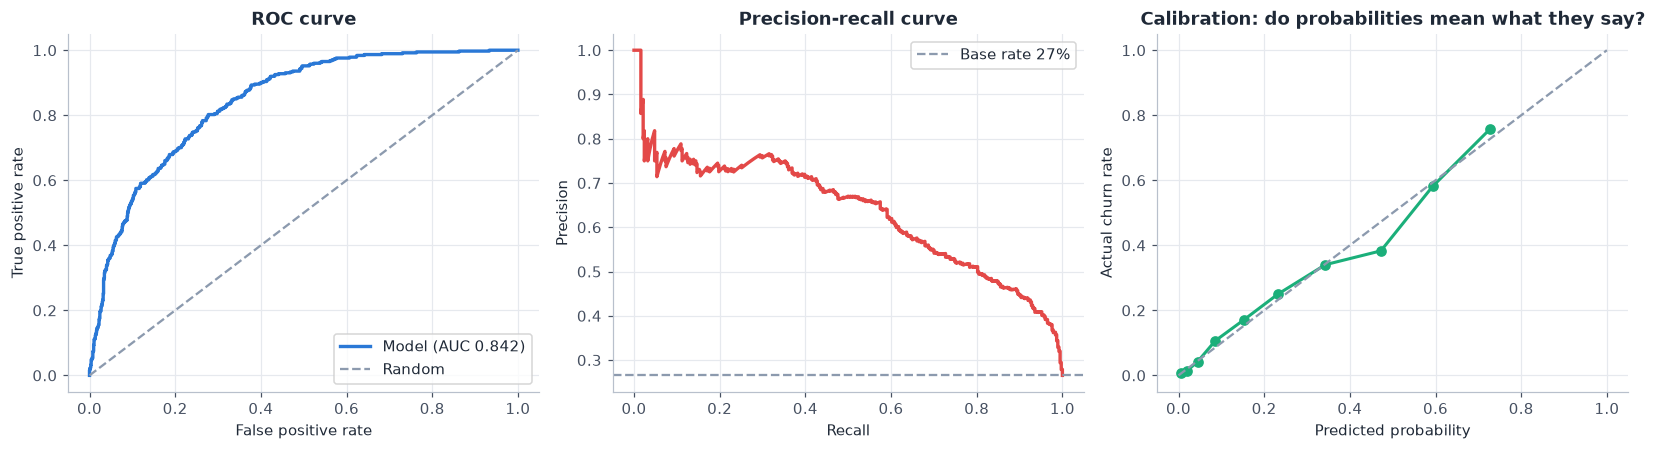

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
fpr, tpr, _ = roc_curve(yte, p_te); ax[0].plot(fpr, tpr, color=BLUE, lw=2.2, label=f'Model (AUC {roc_auc_score(yte, p_te):.3f})'); ax[0].plot([0, 1], [0, 1], color=GREY, ls='--', label='Random')
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].set_title('ROC curve'); ax[0].legend()
pre, rec, _ = precision_recall_curve(yte, p_te); ax[1].plot(rec, pre, color=RED, lw=2.2); ax[1].axhline(yte.mean(), color=GREY, ls='--', label=f'Base rate {yte.mean():.0%}')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-recall curve'); ax[1].legend()
fr, mp = calibration_curve(yte, p_te, n_bins=10, strategy='quantile'); ax[2].plot(mp, fr, 'o-', color=GREEN, lw=2); ax[2].plot([0, 1], [0, 1], color=GREY, ls='--')
ax[2].set_xlabel('Predicted probability'); ax[2].set_ylabel('Actual churn rate'); ax[2].set_title('Calibration: do probabilities mean what they say?')
plt.tight_layout(); save('07_model_curves')

## 6. Gains and lift: how much better than random contact?
If the team can only call the top 20% of customers by risk, how many churners do they reach?

,customers,churners,churn_rate,avg_score,lift,cum_share_of_churners_%
decile,,,,,,
1,141,107,0.759,0.728,2.859,28.610
2,141,82,0.582,0.593,2.191,50.535
3,141,54,0.383,0.472,1.443,64.973
4,141,48,0.340,0.343,1.283,77.807
5,141,36,0.255,0.232,0.962,87.433
6,140,23,0.164,0.152,0.619,93.583
7,141,15,0.106,0.086,0.401,97.594
8,141,6,0.043,0.045,0.160,99.198
9,141,2,0.014,0.020,0.053,99.733


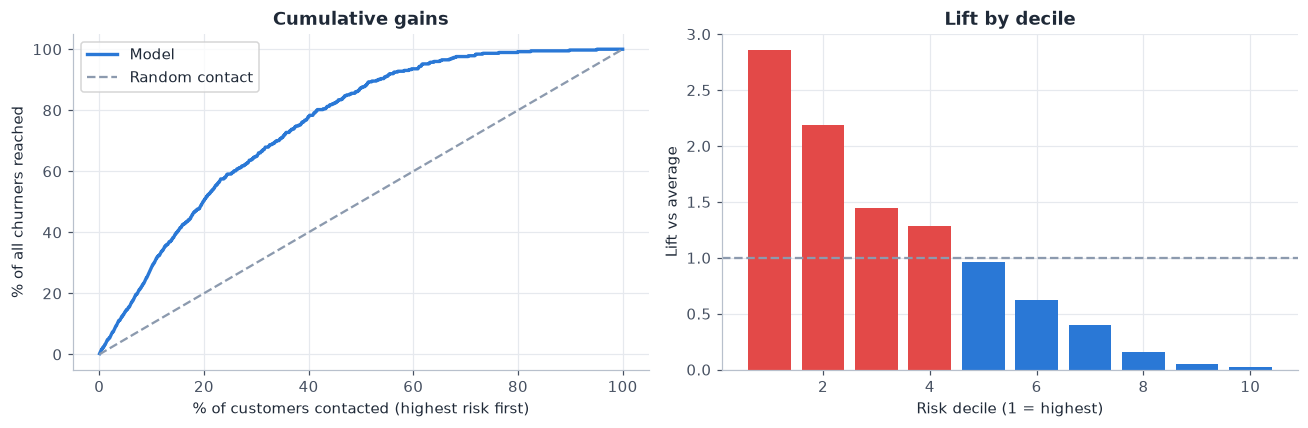

In [9]:
order = np.argsort(-p_te); ys = yte.values[order]
cum = np.cumsum(ys) / ys.sum(); pct = np.arange(1, len(ys) + 1) / len(ys)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(pct * 100, cum * 100, color=BLUE, lw=2.2, label='Model'); ax[0].plot([0, 100], [0, 100], color=GREY, ls='--', label='Random contact')
ax[0].set_xlabel('% of customers contacted (highest risk first)'); ax[0].set_ylabel('% of all churners reached'); ax[0].set_title('Cumulative gains'); ax[0].legend()
dec = pd.DataFrame({'p': p_te, 'y': yte.values}); dec['decile'] = pd.qcut(dec.p.rank(method='first', ascending=False), 10, labels=range(1, 11))
dt = dec.groupby('decile', observed=True).agg(customers=('y', 'size'), churners=('y', 'sum'), churn_rate=('y', 'mean'), avg_score=('p', 'mean'))
dt['lift'] = dt.churn_rate / yte.mean(); dt['cum_share_of_churners_%'] = dt.churners.cumsum() / dt.churners.sum() * 100
ax[1].bar(dt.index.astype(int), dt.lift, color=[RED if v > 1 else BLUE for v in dt.lift]); ax[1].axhline(1, color=GREY, ls='--'); ax[1].set_xlabel('Risk decile (1 = highest)'); ax[1].set_ylabel('Lift vs average'); ax[1].set_title('Lift by decile')
plt.tight_layout(); save('08_gains_lift'); dt.round(3).to_csv(TABLES / 'decile_table.csv'); dt.round(3)

**Finding.** The 20% of customers with the highest scores contain **50.5% of all churners**; the top 40% contain **78%**. The top decile churns at 76%, 2.9 times the average, while the bottom three deciles are almost all loyal (under 5% churn).

## 7. Turn probabilities into a decision: the campaign threshold
A 0.5 cut-off is arbitrary. Contacting a customer costs money; a saved churner earns money. We choose the cut-off that maximises **net value** using assumptions stated in `src/churn/config.py`.

The threshold is chosen on **out-of-fold predictions from the training set**, then applied to the test set, so the test result is not tuned on itself.

Assumptions: {'offer_cost': 50.0, 'offer_success_rate': 0.3, 'horizon_months': 12}
chosen threshold (from training out-of-fold): 0.27


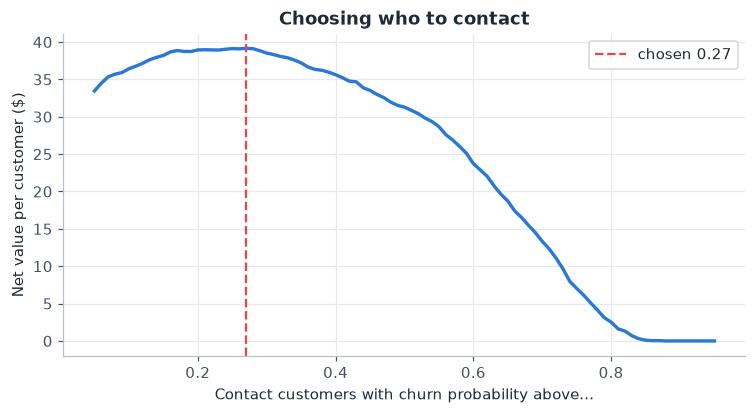

In [10]:
print('Assumptions:', ASSUMPTIONS)
kw = dict(offer_cost=ASSUMPTIONS['offer_cost'], success_rate=ASSUMPTIONS['offer_success_rate'], horizon_months=ASSUMPTIONS['horizon_months'])
oof = cross_val_predict(clone(final), Xtr, ytr, cv=cv, method='predict_proba')[:, 1]
thr, v_tr, grid = best_threshold(ytr.values, oof, Xtr['MonthlyCharges'].values, **kw)
print(f'chosen threshold (from training out-of-fold): {thr:.2f}')
ths = [g[0] for g in grid]; net = [g[1]['net'] / len(ytr) for g in grid]
plt.figure(figsize=(8, 3.8)); plt.plot(ths, net, color=BLUE, lw=2.2); plt.axvline(thr, color=RED, ls='--', label=f'chosen {thr:.2f}')
plt.xlabel('Contact customers with churn probability above...'); plt.ylabel('Net value per customer ($)'); plt.title('Choosing who to contact'); plt.legend(); save('09_threshold_choice')

In [11]:
mon = Xte['MonthlyCharges'].values
strategies = {
    'Do nothing': {'contacted': 0, 'true_churners_reached': 0, 'gain': 0.0, 'cost': 0.0, 'net': 0.0},
    'Contact everyone': campaign_value(yte, np.ones(len(yte)), mon, 0.5, **kw),
    'Contact all month-to-month customers': campaign_value(yte, (Xte['Contract'] == 'Month-to-month').astype(float).values, mon, 0.5, **kw),
    f'Model-targeted (threshold {thr:.2f})': campaign_value(yte, p_te, mon, thr, **kw),
}
st = pd.DataFrame(strategies).T
st['net_per_1000_customers'] = (st.net / len(yte) * 1000).round(0)
st['churners_reached_%'] = (st.true_churners_reached / yte.sum() * 100).round(1)
st = st.round(0); st.to_csv(TABLES / 'campaign_strategies_test.csv'); st

,contacted,true_churners_reached,gain,cost,net,net_per_1000_customers,churners_reached_%
Do nothing,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Contact everyone,1409.0,374.0,97974.0,70450.0,27524.0,19534.0,100.0
Contact all month-to-month customers,773.0,329.0,83946.0,38650.0,45296.0,32147.0,88.0
Model-targeted (threshold 0.27),571.0,293.0,80587.0,28550.0,52037.0,36932.0,78.0


**Finding.** Under the stated assumptions, targeting by model scores yields **about $36.9k net per 1,000 customers**, against $32.1k for contacting every month-to-month customer and $19.5k for contacting everyone. The model adds roughly $4.8k per 1,000 customers (+15%) over the simple contract rule. That is useful but modest: the rule of thumb is a strong fallback, and the model's real advantage is ranking within groups so the best-value calls come first.

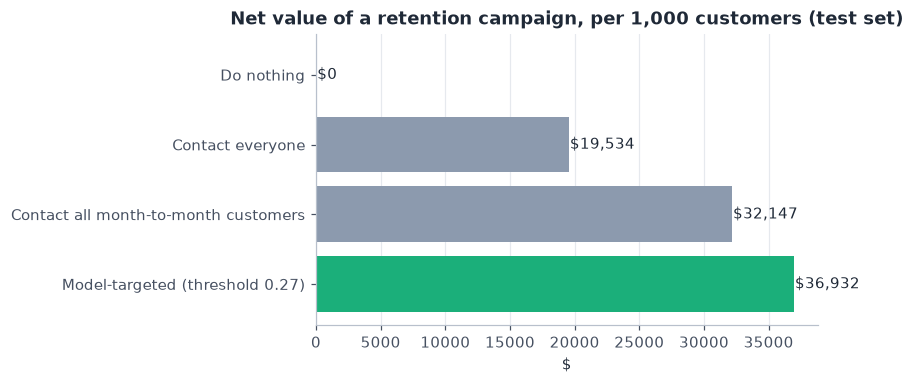

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6)); s = st['net_per_1000_customers']
ax.barh(s.index[::-1], s.values[::-1], color=[GREEN if v == s.max() else GREY for v in s.values[::-1]])
for i, v in enumerate(s.values[::-1]): ax.text(v + 100, i, f'${v:,.0f}', va='center')
ax.set_title('Net value of a retention campaign, per 1,000 customers (test set)'); ax.set_xlabel('$'); ax.grid(axis='y', visible=False)
plt.tight_layout(); save('10_campaign_strategies')

## 8. What drives the predictions?

,feature,auc_drop,sd
0,tenure,0.1682,0.0058
13,InternetService,0.0512,0.0077
14,Contract,0.0358,0.0046
2,TotalCharges,0.0126,0.0025
11,PhoneService,0.0044,0.0013
16,PaymentMethod,0.0036,0.0015
17,OnlineSecurity,0.0034,0.0015
15,PaperlessBilling,0.0027,0.0013
20,TechSupport,0.0026,0.0014
1,MonthlyCharges,0.0019,0.0008


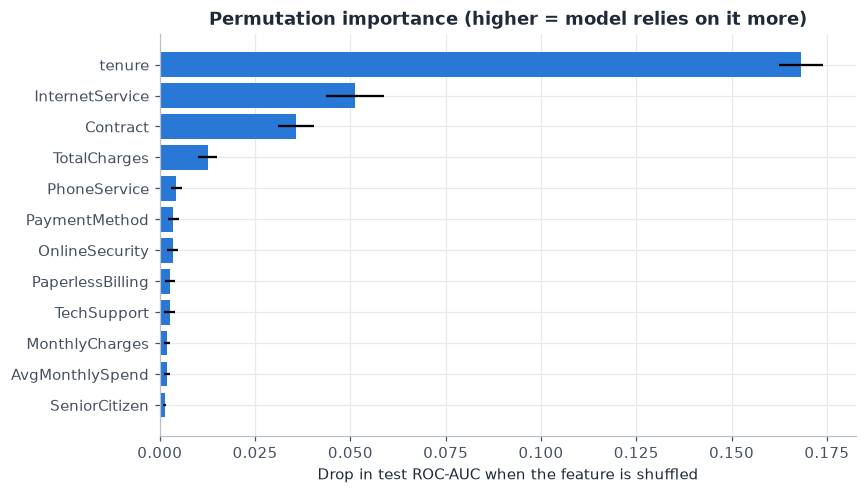

In [13]:
pi = permutation_importance(final, Xte, yte, scoring='roc_auc', n_repeats=15, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({'feature': Xte.columns, 'auc_drop': pi.importances_mean, 'sd': pi.importances_std}).sort_values('auc_drop', ascending=False)
imp.round(4).to_csv(TABLES / 'permutation_importance.csv', index=False)
top = imp.head(12)[::-1]
plt.figure(figsize=(8, 4.6)); plt.barh(top.feature, top.auc_drop, xerr=top.sd, color=BLUE)
plt.xlabel('Drop in test ROC-AUC when the feature is shuffled'); plt.title('Permutation importance (higher = model relies on it more)'); plt.tight_layout(); save('11_permutation_importance')
imp.head(12).round(4)

**Finding.** Tenure dominates: shuffling it alone costs 0.17 ROC-AUC, more than three times any other feature. Internet service (0.05) and contract (0.04) follow; everything else matters little once these are known.

In [14]:
# For the logistic regression we can also read direction and size: odds ratios per feature
assert final_name.startswith('Logistic'), 'odds ratios are only defined for the logistic model'
names = final.named_steps['prep'].get_feature_names_out(); coef = final.named_steps['m'].coef_[0]
orr = pd.DataFrame({'feature': names, 'odds_ratio': np.exp(coef)}).assign(abs_log=lambda d: np.abs(np.log(d.odds_ratio))).sort_values('abs_log', ascending=False).head(14)
orr[['feature', 'odds_ratio']].round(3).to_csv(TABLES / 'odds_ratios.csv', index=False)
print('numeric features are standardised: odds ratio is per 1 standard deviation (above 1 = more likely to churn)')
orr[['feature', 'odds_ratio']].round(3).set_index('feature')

numeric features are standardised: odds ratio is per 1 standard deviation (above 1 = more likely to churn)


,odds_ratio
feature,
tenure,0.293
InternetService_No,0.416
InternetService_Fiber optic,2.400
Contract_Month-to-month,1.994
Contract_Two year,0.512
TotalCharges,1.653
PhoneService_Yes,0.619
OnlineSecurity_Yes,0.680
PaperlessBilling_Yes,1.452


## 9. Fairness and stability checks
Gender should not drive decisions, and senior citizens are a protected-style group that could be treated differently. We check whether the model ranks customers equally well in each group, and whether it flags them at similar rates.

In [15]:
chk = []
for col in ['gender', 'SeniorCitizen', 'Contract']:
    for g, idx in Xte.groupby(col).groups.items():
        yy, pp = yte.loc[idx], p_te[Xte.index.get_indexer(idx)]
        flagged = (pp >= thr).mean()
        chk.append({'group': col, 'value': g, 'customers': len(idx), 'actual_churn_%': round(yy.mean() * 100, 1), 'flagged_%': round(flagged * 100, 1),
                    'roc_auc': round(roc_auc_score(yy, pp), 3) if yy.nunique() > 1 else np.nan, 'recall_at_threshold': round(((pp >= thr) & (yy == 1)).sum() / max(yy.sum(), 1), 3)})
fair = pd.DataFrame(chk); fair.to_csv(TABLES / 'fairness_check.csv', index=False); fair

,group,value,customers,actual_churn_%,flagged_%,roc_auc,recall_at_threshold
0,gender,Female,687,28.1,40.5,0.839,0.777
1,gender,Male,722,25.1,40.6,0.846,0.790
2,SeniorCitizen,No,1187,23.3,35.5,0.842,0.732
3,SeniorCitizen,Yes,222,44.1,67.6,0.786,0.929
4,Contract,Month-to-month,773,42.6,70.4,0.744,0.866
5,Contract,One year,300,12.0,9.0,0.744,0.222
6,Contract,Two year,336,2.7,0.0,0.755,0.000


**Findings.**
- **No gender gap:** AUC 0.839 vs 0.846 and flag rates of 40.5% vs 40.6%.
- **Senior citizens** are flagged far more often (68% vs 36%), which matches their real churn (44% vs 23%), but the model ranks seniors less well (AUC 0.79 vs 0.84). Actions for this group should be supportive (price lock, a proactive call) and reviewed by a person, never restrictive.
- Within each contract type AUC stays around 0.74-0.76, so the model is doing more than re-labelling contract type.

In [16]:
# Stability: bootstrap confidence interval for test ROC-AUC and PR-AUC
from sklearn.metrics import average_precision_score
rng = np.random.default_rng(RANDOM_STATE); a, b = [], []
yv = yte.values
for _ in range(500):
    i = rng.integers(0, len(yv), len(yv)); a.append(roc_auc_score(yv[i], p_te[i])); b.append(average_precision_score(yv[i], p_te[i]))
ci = {'roc_auc_95ci': np.percentile(a, [2.5, 97.5]).round(3).tolist(), 'pr_auc_95ci': np.percentile(b, [2.5, 97.5]).round(3).tolist()}
ci

{'roc_auc_95ci': [0.819, 0.864], 'pr_auc_95ci': [0.585, 0.685]}

## 10. Save the model and metrics

In [17]:
joblib.dump(final, MODELS / 'churn_model.joblib')
metrics = {'final_model': final_name, 'threshold': thr, 'test': res.loc['Final model'].to_dict(), 'baseline_test': res.loc['Baseline'].to_dict(),
           'bootstrap_ci': ci, 'cv_table': cvres.to_dict('index'), 'assumptions': ASSUMPTIONS,
           'train_rows': int(len(Xtr)), 'test_rows': int(len(Xte)), 'test_churn_rate': float(yte.mean())}
with open(FIG.parent / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, default=float)
print('saved model + metrics'); metrics['test']

saved model + metrics


{'roc_auc': 0.8423, 'pr_auc': 0.6361, 'brier': 0.1379, 'precision': 0.6592, 'recall': 0.5535, 'f1': 0.6017}